# Aishell-1 Dataset

In [1]:
import os
import sys
import torchaudio
import torchaudio.transforms as T
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from IPython.display import Audio, display

# make `utils` and `data` importable (project root and training/)
for path in (os.path.abspath('../..'), os.path.abspath('..')):
    if path not in sys.path:
        sys.path.append(path)

In [2]:
!tree data_aishell/wav/train | wc -l

3


In [3]:
!tree data_aishell/wav/val | wc -l

3


In [4]:
import os
os.chdir("..")
#next(os.walk("data_aishell/wav/train"))[1]

sizes = []
for _, dirnames, filenames in os.walk("../data_aishell/wav/train"):
    sizes.append(len(filenames))

np.array(sizes)

array([  0, 354, 365, 357, 338, 360, 348, 317, 351, 346, 351, 353, 365,
       359, 351, 352, 351, 364, 362, 353, 344, 348, 344, 358, 348, 346,
       362, 364, 350, 339, 312, 336, 331, 345, 357, 336, 337, 344, 333,
       334, 347, 332, 327, 339, 337, 325, 328, 343, 342, 357])

In [5]:
import linecache as lc
from utils.to_pinyin import to_pinyin

line = lc.getline("../data_aishell/transcript/aishell_transcript_v0.8.txt", 356)

print(line.rsplit())
pure_chars = ' '.join(line.rsplit()[1:])

print(f'{pure_chars}: {to_pinyin(pure_chars)}')

In [6]:
def get_transcript(transcript_path, filename):
    with open(transcript_path, encoding="utf-8") as f:
        while line := f.readline().rsplit():
            if line[0] == filename[:-4]:
                chars = ' '.join(line[1:])
                return chars, to_pinyin(chars)

get_transcript("../data_aishell/transcript/aishell_transcript_v0.8.txt", "BAC009S0002W0122.wav")

torch.Size([1, 95984])

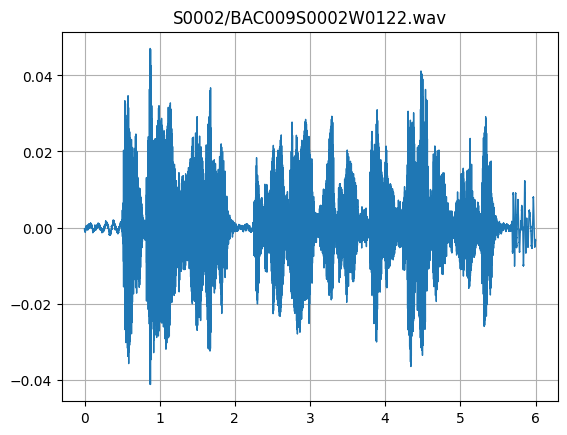

In [7]:
y, sr = torchaudio.load('../data_aishell/wav/train/S0002/BAC009S0002W0122.wav')

waveform = y.numpy()
num_channels, num_frames = waveform.shape

time_axis = torch.arange(0, num_frames) / sr

fig, axes = plt.subplots(num_channels, 1)

axes = [axes]
axes[0].plot(time_axis, waveform[0], linewidth=1)
axes[0].grid(True)
axes[0].set_title("S0002/BAC009S0002W0122.wav")

y.shape

In [8]:
from data.aishell_dataset import AishellDataset

from utils.to_pinyin import to_pinyin

dataset = AishellDataset(path="../data_aishell", sample_rate=44100, n_mels=80)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

mel, transcript = dataset[0]
print(mel.shape)
print(transcript)

y, sr = torchaudio.load(dataset.wav_files[0])
display(Audio(y.numpy(), rate=sr))

mfcc_transform = T.MFCC(
    sample_rate=sr,
    n_mfcc=13,
    melkwargs={"n_mels": 80, "n_fft": 512, "hop_length": int(sr * 0.01)}
)
mfcc = mfcc_transform(y)

fig, axes = plt.subplots(3, 1, figsize=(12, 8))
fig.suptitle(to_pinyin(transcript), fontsize=14)

axes[0].plot(y.squeeze().numpy())
axes[0].set_title("Waveform")
axes[0].set_xlabel("Sample")
axes[0].set_ylabel("Amplitude")

axes[1].imshow(mel.T.numpy(), aspect="auto", origin="lower")
axes[1].set_title("Log Mel Spectrogram")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Mel bin")

axes[2].imshow(mfcc.squeeze().numpy(), aspect="auto", origin="lower")
axes[2].set_title("MFCC")
axes[2].set_xlabel("Time")
axes[2].set_ylabel("MFCC coeff")

plt.tight_layout()
plt.show()

In [9]:
import glob
import os
import random

ROOT = os.path.abspath("../..")

wavs = sorted(glob.glob(os.path.join(ROOT, "data_aishell/wav/train/*/*.wav")))
random.seed(33886)  # powtarzalny wybor probki; usun, by losowac za kazdym razem
sample_wav = random.choice(wavs)
utt_id = os.path.splitext(os.path.basename(sample_wav))[0]

transcripts = {}
with open(os.path.join(ROOT, "data_aishell/transcript/aishell_transcript_v0.8.txt"), encoding="utf-8") as f:
    for line in f:
        key, _, text = line.strip().partition(" ")
        transcripts[key] = text.replace(" ", "")

sample_transcript = transcripts[utt_id]
print(utt_id, sample_transcript)

In [10]:
from utils.visualise_tones import visualize_tones

fig_waveform, fig_spectrogram = visualize_tones(
    wav_path=sample_wav,
    transcript=sample_transcript,
    save_prefix=os.path.join(ROOT, "img/aishell_sample")  # zapisuje *_waveform.png i *_spectrogram.png
)